# Phase 1: ZINC-250K Dataset Analysis

### Objective
Load the dataset, strip newlines, calculate basic statistics, bin molecules by QED, and save the processed dataset.

In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
import sys
import os
import json
sys.path.append(os.path.abspath(".."))
from src.chemistry.properties import calculate_qed, calculate_sas

In [2]:
# Load ZINC dataset
df = pd.read_csv("../data/raw/zinc_250k.csv")
print(f"Total original rows: {len(df)}")

Total original rows: 249455


### Clean and Validate SMILES
We will take a reproducible 1,000-molecule sample for fast mid-review analysis, while the complete 249,455-molecule dataset will be used for final preprocessing/training.

In [3]:
df_sample = df.sample(1000, random_state=42).copy()
df_sample["smiles"] = df_sample["smiles"].str.strip()

# Convert to RDKit Mols
df_sample["mol"] = df_sample["smiles"].apply(Chem.MolFromSmiles)
valid_count = df_sample["mol"].notna().sum()
print(f"Valid molecules in sample: {valid_count} / {len(df_sample)}")

# Filter out invalid
df_valid = df_sample[df_sample["mol"].notna()].copy()

Valid molecules in sample: 1000 / 1000


### Calculate QED and SAS

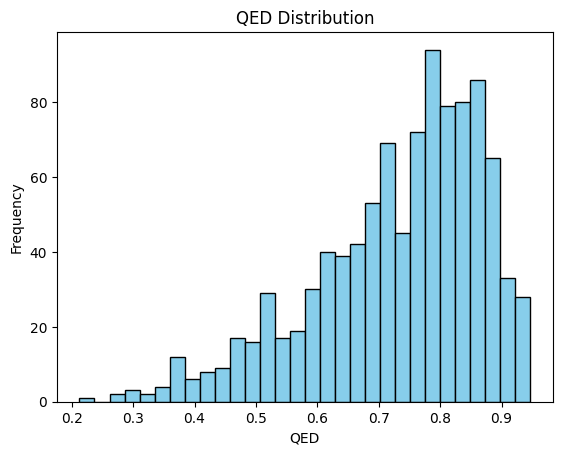

In [4]:
df_valid["qed"] = df_valid["mol"].apply(calculate_qed)
df_valid["sas"] = df_valid["mol"].apply(calculate_sas)

plt.hist(df_valid["qed"], bins=30, color="skyblue", edgecolor="black")
plt.title("QED Distribution")
plt.xlabel("QED")
plt.ylabel("Frequency")
plt.show()

In [5]:
low_qed = len(df_valid[df_valid["qed"] < 0.5])
med_qed = len(df_valid[(df_valid["qed"] >= 0.5) & (df_valid["qed"] < 0.7)])
high_qed = len(df_valid[(df_valid["qed"] >= 0.7) & (df_valid["qed"] < 0.85)])
print(f"Low QED: {low_qed}\nMedium QED: {med_qed}\nHigh QED: {high_qed}")

Low QED: 75
Medium QED: 271
High QED: 446


### Save Processed Dataset and Statistics

In [6]:
stats = {
    "total_rows_processed": len(df_valid),
    "low_qed_count": low_qed,
    "med_qed_count": med_qed,
    "high_qed_count": high_qed
}
with open("../data/processed/dataset_stats.json", "w") as f:
    json.dump(stats, f)

# Save without the mol object
df_out = df_valid.drop(columns=["mol"])
df_out.to_csv("../data/processed/zinc_processed.csv", index=False)
print("Processed dataset and statistics saved to data/processed/")

Processed dataset and statistics saved to data/processed/
